# Part 2 — Non-Premixed Flames: $T(Z)$ at Increasing Scalar Dissipation Rate

H$_2$/air counterflow diffusion flames (`h2o2.yaml`, 300 K streams, 1 atm, 2 cm gap), compared with the equilibrium envelope $T_\mathrm{eq}(Z)$.

Functions live in `src/ct_utils/opposed_premixed_flame` (flames) and `src/ct_utils/plots`. Tables go to `results/part2/raw/`, figures to `results/part2/figures/{pdf,jpeg}/`.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import ct_utils
from ct_utils import general as eq
from ct_utils import opposed_premixed_flame as cf
from ct_utils import plots

ct_utils.set_part("part2")      # outputs go to results/part2/
plots.set_style()
%matplotlib inline

## Step 1 — Family of counterflow flames

**`cf.solve_counterflow(strain_rate, mechanism, fuel, T_fuel, T_ox, p, width)`** solves one flame. Both inlets get $\dot m = a\,\tfrac{L}{2}\,\tfrac{\rho_f + \rho_{ox}}{2}$; the grid is refined with `ratio=3, slope=0.05, curve=0.1`.

**`cf.flame_to_dataframe(flame)`** exports the profiles with `to_pandas()` plus $x$, $u$, $Z$, $\chi$; saved with `eq.save_dataframe`.

In [2]:
strain_rates = [50, 200, 500, 1000, 2000]          # 1/s
flames = {a: cf.solve_counterflow(a) for a in strain_rates}

for a, flame in flames.items():
    eq.save_dataframe(cf.flame_to_dataframe(flame), f"flame_a{a}")

print({a: f"{f.T.max():.0f} K" for a, f in flames.items()})

{50: '2365 K', 200: '2164 K', 500: '2003 K', 1000: '1873 K', 2000: '1733 K'}


## Step 2 — $T(Z)$ and $\chi_\mathrm{st}$

**`cf.extract_TZ_profile(flame, fuel, oxidizer)`** returns $Z$ (Bilger), $T$ and $\chi_\mathrm{st}$, read at the grid point closest to $Z_\mathrm{st}$. Helpers: **`cf.stoichiometric_mixture_fraction()`** gives $Z_\mathrm{st}$, **`cf.scalar_dissipation_rate(flame)`** gives $\chi(x)$, and **`cf.chi_st_analytic(a, Z_st)`** gives the constant-density estimate for comparison.

$$
\chi = 2D\,|\nabla Z|^2, \qquad D = \frac{k}{\rho c_p}, \qquad
\chi_\mathrm{st}^\mathrm{an} = \frac{a}{\pi}\exp\!\left(-2\left[\mathrm{erf}^{-1}(1 - 2Z_\mathrm{st})\right]^2\right)
$$

| Symbol | Meaning | SI unit |
|---|---|---|
| $\chi$, $\chi_\mathrm{st}$ | Scalar dissipation rate (at $Z_\mathrm{st}$) | 1/s |
| $D$ | Mixture diffusivity (unity Lewis number) | m²/s |
| $k$, $\rho$, $c_p$ | Conductivity, density, specific heat | W/(m·K), kg/m³, J/(kg·K) |
| $Z$, $Z_\mathrm{st}$ | Mixture fraction, stoichiometric value | – |
| $a$ | Strain rate | 1/s |

In [3]:
Z_st = cf.stoichiometric_mixture_fraction()
profiles = {a: cf.extract_TZ_profile(f) for a, f in flames.items()}

summary = pd.DataFrame({
    "a (1/s)": strain_rates,
    "a_max measured (1/s)": [flames[a].strain_rate("max") for a in strain_rates],
    "chi_st (1/s)": [profiles[a][2] for a in strain_rates],
    "chi_st analytic (1/s)": cf.chi_st_analytic(strain_rates, Z_st),
    "T_max (K)": [profiles[a][1].max() for a in strain_rates],
    "Z at T_max": [profiles[a][0][np.argmax(profiles[a][1])] for a in strain_rates],
})
eq.save_dataframe(summary, "summary")
print(f"Z_st = {Z_st:.4f}\n")
print(summary.to_string(index=False, float_format="%.4g"))

Z_st = 0.0285

 a (1/s)  a_max measured (1/s)  chi_st (1/s)  chi_st analytic (1/s)  T_max (K)  Z at T_max
      50                   827        0.9155                 0.4257       2365      0.0317
     200                  2829         3.559                  1.703       2164     0.03214
     500                  6223         8.787                  4.257       2003     0.03219
    1000             1.159e+04         17.33                  8.514       1873     0.03218
    2000             2.308e+04         33.87                  17.03       1733     0.03238


## Step 3 — Equilibrium envelope

**`cf.equilibrium_T_of_Z(Z_range, ...)`** blends the streams by mass at each $Z$, blends the enthalpy the same way ($h = Z h_f + (1-Z) h_{ox}$), and equilibrates at constant $h$, $p$.

In [4]:
Z_eq = np.concatenate([np.linspace(0, 0.1, 201), np.linspace(0.1, 1, 181)[1:]])
T_eq = cf.equilibrium_T_of_Z(Z_eq)
eq.save_dataframe(pd.DataFrame({"Z": Z_eq, "T_eq": T_eq}), "T_eq_of_Z")
print(f"T_eq max = {T_eq.max():.0f} K at Z = {Z_eq[np.argmax(T_eq)]:.4f}")

T_eq max = 2402 K at Z = 0.0305


## Step 4 — Family plot

Left: the requested figure ($Z \in [0, 1]$). Right: the same on a log $Z$ axis, where the reaction zone near $Z_\mathrm{st}$ is visible.

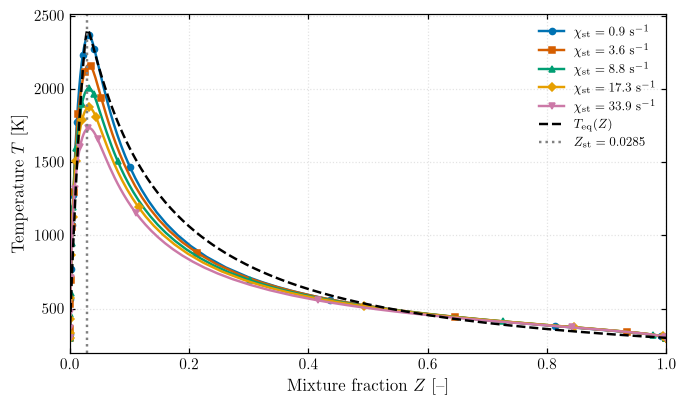

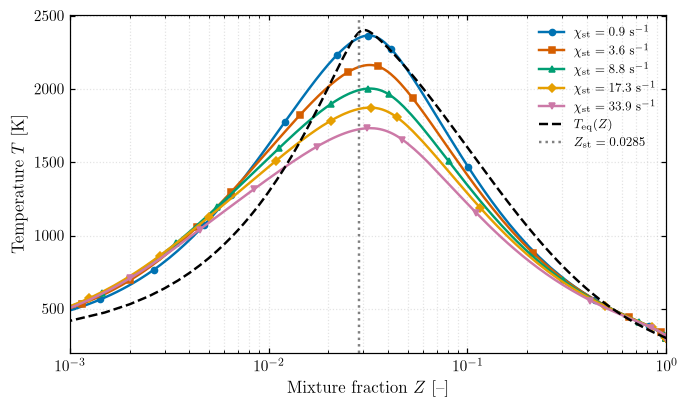

In [5]:
labels = [rf"$\chi_\mathrm{{st}} = {profiles[a][2]:.1f}$ s$^{{-1}}$" for a in strain_rates]
Zs = [profiles[a][0] for a in strain_rates]
Ts = [profiles[a][1] for a in strain_rates]

def family_plot(ax, xscale, xlim):
    plots.plot(Zs, Ts, r"Mixture fraction $Z$ [--]", r"Temperature $T$ [K]", ax=ax,
               labels=labels, xscale=xscale, markevery=15, legend=False)
    ax.plot(Z_eq, T_eq, "k--", marker="none", label=r"$T_\mathrm{eq}(Z)$")
    ax.axvline(Z_st, ls=":", color="0.5", marker="none", label=rf"$Z_\mathrm{{st}} = {Z_st:.4f}$")
    ax.set_xlim(*xlim)
    ax.legend(fontsize=8)

fig, ax = plt.subplots(figsize=(7, 4))
family_plot(ax, "linear", (0, 1))
plots.save_figure(fig, "part2_T_vs_Z")
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
family_plot(ax, "log", (1e-3, 1))
plots.save_figure(fig, "part2_T_vs_Z_logZ")
plt.show()

## Extinction

A solution that has extinguished collapses to pure mixing: $T_\mathrm{max}$ drops to the inlet temperature. Scanning higher strain rates locates where that happens.

 a (1/s)  chi_st (1/s)  T_max (K)  burning
    2000         33.87       1733     True
    3000         50.25       1643     True
    4000         65.41       1573     True
    5000         81.29       1506     True
    6000        0.4273        300    False
    7000        0.3659      300.1    False
    8000        0.3192      300.9    False
    9000         0.283      300.1    False
   10000        0.2509      300.9    False


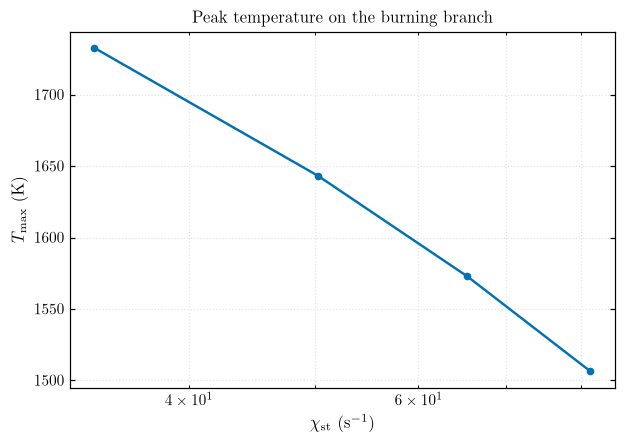

In [6]:
a_scan = np.array([2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, 10000])
scan = []
for a in a_scan:
    f = cf.solve_counterflow(a)
    Z, T, chi = cf.extract_TZ_profile(f)
    scan.append({"a (1/s)": a, "chi_st (1/s)": chi, "T_max (K)": T.max(), "burning": T.max() > 1000})
scan = pd.DataFrame(scan)
eq.save_dataframe(scan, "extinction_scan")
print(scan.to_string(index=False, float_format="%.4g"))

burn = scan[scan.burning]
fig, ax = plots.plot(burn["chi_st (1/s)"], burn["T_max (K)"], r"$\chi_\mathrm{st}$ (s$^{-1}$)",
                     r"$T_\mathrm{max}$ (K)", legend=False, xscale="log",
                     title="Peak temperature on the burning branch")
plots.save_figure(fig, "part2_Tmax_vs_chi")
plt.show()

## Answers

**1. Why is $T_\mathrm{eq}(Z)$ asymmetric?** On a linear $Z$ axis the drop is actually steeper toward $Z = 0$, because $Z_\mathrm{st} = 0.0285$ is so small. Toward $Z = 1$ it decays slowly. With complete combustion (Burke–Schumann), the temperature rise varies linearly on each side of $Z_\mathrm{st}$:

$$
T - T_\mathrm{mix} \propto \frac{Z}{Z_\mathrm{st}}\ (Z < Z_\mathrm{st}), \qquad
T - T_\mathrm{mix} \propto \frac{1 - Z}{1 - Z_\mathrm{st}}\ (Z > Z_\mathrm{st})
$$

| Symbol | Meaning | SI unit |
|---|---|---|
| $T$ | Burned temperature | K |
| $T_\mathrm{mix}$ | Temperature of the unburned blend at $Z$ | K |
| $Z$, $Z_\mathrm{st}$ | Mixture fraction, stoichiometric value | – |

The lean branch climbs from $Z = 0$ to $0.0285$, so it is steep. The rich branch spreads the fixed heat release over the extra fuel mass all the way to $Z = 1$. Heat release is limited by the fuel on the lean side and by O$_2$ on the rich side.

**2. Does the peak shift with $\chi_\mathrm{st}$?** Slightly richer: $Z(T_\mathrm{max})$ goes from $0.0317$ to $0.0324$ as $\chi_\mathrm{st}$ goes from 0.9 to 34 s$^{-1}$, and to $0.0336$ just before extinction. Higher strain lets unburned H$_2$ leak through the reaction zone. H$_2$ diffuses fast, so the zone where heat release balances losses moves toward the fuel side.

**3. The area between $T(Z)$ and $T_\mathrm{eq}(Z)$** is the enthalpy not yet released as heat, because of incomplete combustion and dissociation not recombining. Its size is set by the Damköhler number $\mathrm{Da} \sim \tau_\mathrm{mix}/\tau_\mathrm{chem} \sim 1/(\chi_\mathrm{st}\,\tau_\mathrm{chem})$: higher $\chi_\mathrm{st}$ gives less time for chemistry and a larger gap.

**4. Closest to extinction:** the burning branch ends between $a = 5000$ s$^{-1}$ ($\chi_\mathrm{st} \approx 81$ s$^{-1}$, $T_\mathrm{max} \approx 1506$ K) and $a = 6000$ s$^{-1}$, where the solution collapses to pure mixing. Of the main five, $\chi_\mathrm{st} = 33.9$ s$^{-1}$ is closest. You detect it in the flame object by `flame.T.max()` dropping to the inlet temperature (and the heat release, `flame.heat_release_rate`, going to zero). This scan restarts every solve from scratch; a strain-rate continuation from the last burning solution would pin the limit more precisely.

**5. Why the lowest-strain flame still differs from equilibrium:** (a) $\chi_\mathrm{st} \approx 0.9$ s$^{-1}$ is small but not zero, so the radicals do not fully recombine; (b) mainly differential diffusion. H$_2$ is very light (Lewis number $\approx 0.3$), so it diffuses ahead of heat. The element-based $Z$ is then no longer a conserved enthalpy coordinate, and $T$ even exceeds $T_\mathrm{eq}$ on the lean side ($Z < 0.02$). The equilibrium envelope assumes equal diffusivities.

The measured $\chi_\mathrm{st}$ is about $2\times$ the constant-density analytic value, and the measured maximum strain is about $15\times$ the target $a$. Both come from the large density difference between the H$_2$ and air jets, which the project's equal-mass-flux formula does not account for.
